In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files[:5]:
        print(f"{indent}  {f}")
    if len(files) > 5:
        print(f"{indent}  ... ({len(files)} files total)")

input/
  datasets/
    maitam/
      vietnamese-traffic-signs/
        archive/
          classes_en.txt
          classes.txt
          classes_vie.txt
          labels/
            1893.txt
            1711.txt
            0389.txt
            1773.txt
            0078.txt
            ... (3216 files total)
          images/
            0664.jpg
            1269.jpg
            2193.jpg
            0733.jpg
            2008.jpg
            ... (3216 files total)
          split_dataset/
            test_files.txt
            train_files.txt


In [2]:
import os

BASE = "/kaggle/input/datasets/maitam/vietnamese-traffic-signs/archive"

with open(f"{BASE}/classes.txt", encoding="utf-8") as f:
    classes = [l.strip() for l in f if l.strip()]
print("Số lớp:", len(classes))
print(classes[:10])

with open(f"{BASE}/split_dataset/train_files.txt") as f:
    train_files = [l.strip() for l in f if l.strip()]
with open(f"{BASE}/split_dataset/test_files.txt") as f:
    test_files = [l.strip() for l in f if l.strip()]
print("Train:", len(train_files), "| Test:", len(test_files))
print("Ví dụ tên file:", train_files[0])

sample_label = os.listdir(f"{BASE}/labels")[0]
with open(f"{BASE}/labels/{sample_label}") as f:
    print(f"\nNội dung {sample_label}:")
    print(f.read())

Số lớp: 52
['W.224', 'W.205c', 'P.102', 'R.302a', 'W.205a', 'W.207', 'W.201a', 'P.123a', 'I.434a', 'R.303']
Train: 2552 | Test: 639
Ví dụ tên file: 2495.jpg

Nội dung 1893.txt:
10 0.398958 0.374074 0.027083 0.044444



In [3]:
!pip install -q scikit-image scikit-learn wandb

In [4]:
import os, numpy as np, cv2
from PIL import Image

def load_split_crops(file_list):
    images, labels = [], []
    for fname in file_list:
        img_path = f"{BASE}/images/{fname}"
        label_path = f"{BASE}/labels/{os.path.splitext(fname)[0]}.txt"
        if not os.path.exists(img_path) or not os.path.exists(label_path):
            continue
        img = Image.open(img_path).convert("RGB")
        W, H = img.size
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls_id, cx, cy, w, h = int(parts[0]), *map(float, parts[1:])
                x1, y1 = int((cx - w/2) * W), int((cy - h/2) * H)
                x2, y2 = int((cx + w/2) * W), int((cy + h/2) * H)
                x1, y1, x2, y2 = max(0,x1), max(0,y1), min(W,x2), min(H,y2)
                if x2 <= x1 or y2 <= y1:
                    continue
                crop = img.crop((x1, y1, x2, y2)).resize((64, 64))
                images.append(np.array(crop))
                labels.append(cls_id)
    return np.array(images), np.array(labels)

X_train_img, y_train = load_split_crops(train_files)
X_test_img, y_test = load_split_crops(test_files)
print("Train crops:", X_train_img.shape, "| Test crops:", X_test_img.shape)
print("Số lớp có trong train:", len(set(y_train)), "/ 52")

Train crops: (6689, 64, 64, 3) | Test crops: (1645, 64, 64, 3)
Số lớp có trong train: 52 / 52


In [5]:
import numpy as np

unique_classes = sorted(set(y_train.tolist()) | set(y_test.tolist()))
cls2idx = {c: i for i, c in enumerate(unique_classes)}
y_train_idx = np.array([cls2idx[c] for c in y_train])
y_test_idx = np.array([cls2idx[c] for c in y_test])
n_classes = len(unique_classes)
print("n_classes thực tế dùng để train:", n_classes)

n_classes thực tế dùng để train: 52


**Nhánh 1: HOG features + SVM (cổ điển, không cần GPU)**

In [6]:
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

def extract_hog_batch(images):
    feats = []
    for img in images:
        gray = rgb2gray(img)
        f = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
        feats.append(f)
    return np.array(feats)

t0 = time.time()
X_train_hog = extract_hog_batch(X_train_img)
X_test_hog = extract_hog_batch(X_test_img)
print(f"HOG feature dim: {X_train_hog.shape[1]} | extract time: {time.time()-t0:.1f}s")

svm = LinearSVC(C=1.0, max_iter=5000)
svm.fit(X_train_hog, y_train_idx)

pred_svm = svm.predict(X_test_hog)
acc_svm = accuracy_score(y_test_idx, pred_svm)
f1_svm = f1_score(y_test_idx, pred_svm, average="macro")
print(f"[SVM] accuracy = {acc_svm:.4f} | macro-F1 = {f1_svm:.4f}")

HOG feature dim: 1764 | extract time: 13.2s
[SVM] accuracy = 0.9447 | macro-F1 = 0.9237


**Nhánh 2: CNN (deep, có training curve thật log lên WandB)**

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import wandb

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class SignDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img = self.images[idx].astype(np.float32) / 255.0
        img = torch.tensor(img).permute(2, 0, 1)  # HWC -> CHW
        return img, self.labels[idx]

train_ds = SignDataset(X_train_img, y_train_idx)
test_ds = SignDataset(X_test_img, y_test_idx)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, n_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 64->32
        x = self.pool(F.relu(self.conv2(x)))   # 32->16
        x = self.pool(F.relu(self.conv3(x)))   # 16->8
        x = x.flatten(1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

model = SimpleCNN(n_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
wandb_key = user_secrets.get_secret("WANDB_API_KEY")

import wandb
wandb.login(key=wandb_key)
wandb.init(project="vn-traffic-sign-classification", name="simplecnn-vs-svm")

EPOCHS = 15
for epoch in range(EPOCHS):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    train_loss = total_loss / total
    train_acc = correct / total

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            correct += (out.argmax(1) == labels).sum().item()
            total += imgs.size(0)
    test_acc = correct / total

    wandb.log({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc, "test_acc": test_acc})
    print(f"epoch {epoch+1}/{EPOCHS} | train_loss {train_loss:.4f} | train_acc {train_acc:.4f} | test_acc {test_acc:.4f}")

Device: cuda


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: donghan010106 (donghan010106-fpt-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260717_122938-weot2o94
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run simplecnn-vs-svm
wandb: ⭐️ View project at https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-classification
wandb: 🚀 View run at https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-classification/runs/weot2o94


epoch 1/15 | train_loss 2.3902 | train_acc 0.3591 | test_acc 0.6036
epoch 2/15 | train_loss 1.0075 | train_acc 0.6907 | test_acc 0.8140
epoch 3/15 | train_loss 0.5622 | train_acc 0.8240 | test_acc 0.8802
epoch 4/15 | train_loss 0.3808 | train_acc 0.8792 | test_acc 0.9040
epoch 5/15 | train_loss 0.2719 | train_acc 0.9152 | test_acc 0.9447
epoch 6/15 | train_loss 0.2024 | train_acc 0.9345 | test_acc 0.9532
epoch 7/15 | train_loss 0.1628 | train_acc 0.9495 | test_acc 0.9599
epoch 8/15 | train_loss 0.1300 | train_acc 0.9604 | test_acc 0.9605
epoch 9/15 | train_loss 0.1270 | train_acc 0.9611 | test_acc 0.9611
epoch 10/15 | train_loss 0.1041 | train_acc 0.9647 | test_acc 0.9666
epoch 11/15 | train_loss 0.0786 | train_acc 0.9740 | test_acc 0.9635
epoch 12/15 | train_loss 0.0808 | train_acc 0.9758 | test_acc 0.9544
epoch 13/15 | train_loss 0.0961 | train_acc 0.9686 | test_acc 0.9623
epoch 14/15 | train_loss 0.0647 | train_acc 0.9806 | test_acc 0.9751
epoch 15/15 | train_loss 0.0568 | train_acc

**Macro-F1 cho CNN + bảng so sánh cuối cùng**

In [8]:
from sklearn.metrics import f1_score as sk_f1

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        out = model(imgs)
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

acc_cnn = accuracy_score(all_labels, all_preds)
f1_cnn = sk_f1(all_labels, all_preds, average="macro")

wandb.log({"final/svm_acc": acc_svm, "final/svm_f1_macro": f1_svm,
           "final/cnn_acc": acc_cnn, "final/cnn_f1_macro": f1_cnn})

print("\n=== So sánh cổ điển vs deep (Test set, 52 lớp) ===")
print(f"SVM (HOG features): accuracy={acc_svm:.4f} | macro-F1={f1_svm:.4f}")
print(f"CNN (deep):          accuracy={acc_cnn:.4f} | macro-F1={f1_cnn:.4f}")
wandb.finish()

wandb: updating run metadata



=== So sánh cổ điển vs deep (Test set, 52 lớp) ===
SVM (HOG features): accuracy=0.9447 | macro-F1=0.9237
CNN (deep):          accuracy=0.9781 | macro-F1=0.9465


wandb: uploading history steps 11-15, summary, console lines 11-18
wandb: 
wandb: Run history:
wandb:              epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:      final/cnn_acc ▁
wandb: final/cnn_f1_macro ▁
wandb:      final/svm_acc ▁
wandb: final/svm_f1_macro ▁
wandb:           test_acc ▁▅▆▇▇██████████
wandb:          train_acc ▁▅▆▇▇▇█████████
wandb:         train_loss █▄▃▂▂▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:              epoch 14
wandb:      final/cnn_acc 0.97812
wandb: final/cnn_f1_macro 0.94645
wandb:      final/svm_acc 0.94468
wandb: final/svm_f1_macro 0.92365
wandb:           test_acc 0.97812
wandb:          train_acc 0.98296
wandb:         train_loss 0.0568
wandb: 
wandb: 🚀 View run simplecnn-vs-svm at: https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-classification/runs/weot2o94
wandb: ⭐️ View project at: https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-classification
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wand

**Cài Ultralytics (thư viện train YOLO)**

In [9]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.0 MB/s eta 0:00:00


**Tạo file train/val list trỏ thẳng vào /kaggle/input**

In [10]:
import os

BASE = "/kaggle/input/datasets/maitam/vietnamese-traffic-signs/archive"
WORK = "/kaggle/working"

with open(f"{WORK}/train.txt", "w") as f:
    for fname in train_files:
        f.write(f"{BASE}/images/{fname}\n")

with open(f"{WORK}/val.txt", "w") as f:
    for fname in test_files:
        f.write(f"{BASE}/images/{fname}\n")

yaml_content = f"""
path: {WORK}
train: train.txt
val: val.txt
nc: {len(classes)}
names: {classes}
"""
with open(f"{WORK}/data.yaml", "w", encoding="utf-8") as f:
    f.write(yaml_content)

print(yaml_content[:300])


path: /kaggle/working
train: train.txt
val: val.txt
nc: 52
names: ['W.224', 'W.205c', 'P.102', 'R.302a', 'W.205a', 'W.207', 'W.201a', 'P.123a', 'I.434a', 'R.303', 'P.130', 'I.409', 'R.415a', 'W.245a', 'P.106a*Xe tải', 'W.203c', 'P.117*', 'P.124a*', 'P.107', 'P.124d', 'P.103a', 'W.203b', 'W.221b', '


**Train YOLOv8n (CNN detector), log thẳng lên WandB**

In [11]:
import os
from kaggle_secrets import UserSecretsClient
from ultralytics import YOLO

user_secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = user_secrets.get_secret("WANDB_API_KEY")

model_yolo = YOLO("yolov8n.pt")  # pretrained nhỏ, fine-tune tiếp trên data VN

results = model_yolo.train(
    data=f"{WORK}/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    project="vn-traffic-sign-detection",
    name="yolov8n-finetune",
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.98 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015

**Eval CNN detector (mAP thật trên tập test)**

In [12]:
metrics_yolo = model_yolo.val(data=f"{WORK}/data.yaml", split="val")
print(f"mAP50: {metrics_yolo.box.map50:.4f}")
print(f"mAP50-95: {metrics_yolo.box.map:.4f}")
print(f"Precision: {metrics_yolo.box.mp:.4f}")
print(f"Recall: {metrics_yolo.box.mr:.4f}")

Ultralytics 8.4.98 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,015,788 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 263.6±236.3 MB/s, size: 243.8 KB)
val: Scanning /kaggle/input/datasets/maitam/vietnamese-traffic-signs/archive/labels... 639 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 639/639 566.5it/s 1.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/maitam/vietnamese-traffic-signs/archive is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 7.9it/s 5.0s
                   all        639       1645      0.939      0.846      0.947      0.702
                 W.224         61         61      0.983      0.974      0.989      0.685
                W.205c          5          5      0.939        0.8      0.962       0.55
                 P.102         87         88      0.982      0.8

**Nhánh classical: HSV color threshold + contour shape → tìm bbox, không train gì**

In [13]:
import cv2
import numpy as np

def classical_detect(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    # biển báo VN chủ yếu viền đỏ (cấm/nguy hiểm) hoặc nền xanh dương (hiệu lệnh/chỉ dẫn)
    red_mask1 = cv2.inRange(hsv, (0, 70, 50), (10, 255, 255))
    red_mask2 = cv2.inRange(hsv, (170, 70, 50), (180, 255, 255))
    blue_mask = cv2.inRange(hsv, (100, 70, 50), (130, 255, 255))
    mask = red_mask1 | red_mask2 | blue_mask

    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    H, W = img_bgr.shape[:2]
    min_area = 0.001 * H * W
    boxes = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < min_area:
            continue
        x, y, w, h = cv2.boundingRect(c)
        aspect = w / h if h > 0 else 0
        if 0.5 < aspect < 2.0:  # biển báo thường gần vuông/tròn, loại bỏ vệt dài
            boxes.append((x, y, x+w, y+h))
    return boxes

def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0

tp, fp, fn = 0, 0, 0
for fname in test_files:
    img_path = f"{BASE}/images/{fname}"
    label_path = f"{BASE}/labels/{os.path.splitext(fname)[0]}.txt"
    img = cv2.imread(img_path)
    if img is None:
        continue
    H, W = img.shape[:2]

    gt_boxes = []
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                _, cx, cy, w, h = map(float, parts)
                x1, y1 = (cx - w/2) * W, (cy - h/2) * H
                x2, y2 = (cx + w/2) * W, (cy + h/2) * H
                gt_boxes.append((x1, y1, x2, y2))

    pred_boxes = classical_detect(img)

    matched_gt = set()
    for pb in pred_boxes:
        best_iou, best_idx = 0, -1
        for i, gb in enumerate(gt_boxes):
            if i in matched_gt:
                continue
            cur = iou(pb, gb)
            if cur > best_iou:
                best_iou, best_idx = cur, i
        if best_iou >= 0.5:
            tp += 1
            matched_gt.add(best_idx)
        else:
            fp += 1
    fn += len(gt_boxes) - len(matched_gt)

precision_cls = tp / (tp + fp) if (tp+fp) > 0 else 0
recall_cls = tp / (tp + fn) if (tp+fn) > 0 else 0
f1_cls = 2*precision_cls*recall_cls/(precision_cls+recall_cls+1e-9)
print(f"[Classical detector] precision={precision_cls:.4f} | recall={recall_cls:.4f} | F1={f1_cls:.4f}")

[Classical detector] precision=0.0854 | recall=0.1562 | F1=0.1104


**Tổng hợp cả 4 model lên 1 chỗ, log lên WandB**

In [14]:
import wandb

wandb.init(project="vn-traffic-sign-detection", name="final-comparison")
wandb.log({
    "classical/precision": precision_cls,
    "classical/recall": recall_cls,
    "classical/f1": f1_cls,
    "yolo/mAP50": metrics_yolo.box.map50,
    "yolo/mAP50_95": metrics_yolo.box.map,
    "yolo/precision": metrics_yolo.box.mp,
    "yolo/recall": metrics_yolo.box.mr,
})
wandb.finish()

print("=== TỔNG HỢP 4 MODEL ===")
print(f"Detection - Classical (HSV+contour): P={precision_cls:.4f} R={recall_cls:.4f} F1={f1_cls:.4f}")
print(f"Detection - YOLOv8n (CNN):           mAP50={metrics_yolo.box.map50:.4f} P={metrics_yolo.box.mp:.4f} R={metrics_yolo.box.mr:.4f}")
print(f"Classification - SVM (HOG):          acc={acc_svm:.4f} F1={f1_svm:.4f}")
print(f"Classification - CNN:                acc={acc_cnn:.4f} F1={f1_cnn:.4f}")

wandb: WARNING Changes to your `wandb` environment variables will be ignored because your `wandb` session has already started. For more information on how to modify your settings with `wandb.init()` arguments, please refer to https://wandb.me/wandb-init.
wandb: setting up run akns2x8y
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260717_124907-akns2x8y
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final-comparison
wandb: ⭐️ View project at https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-detection
wandb: 🚀 View run at https://wandb.ai/donghan010106-fpt-university/vn-traffic-sign-detection/runs/akns2x8y
wandb: updating run metadata; uploading summary
wandb: uploading history steps 0-0, summary
wandb: 
wandb: Run history:
wandb:        classical/f1 ▁
wandb: classical/precision ▁
wandb:    classical/recall ▁
wandb:          yolo/mAP50 ▁
wandb:       yolo/mAP50_95 ▁
wandb:      yolo/precision 

=== TỔNG HỢP 4 MODEL ===
Detection - Classical (HSV+contour): P=0.0854 R=0.1562 F1=0.1104
Detection - YOLOv8n (CNN):           mAP50=0.9468 P=0.9390 R=0.8463
Classification - SVM (HOG):          acc=0.9447 F1=0.9237
Classification - CNN:                acc=0.9781 F1=0.9465


**EDA nhanh**

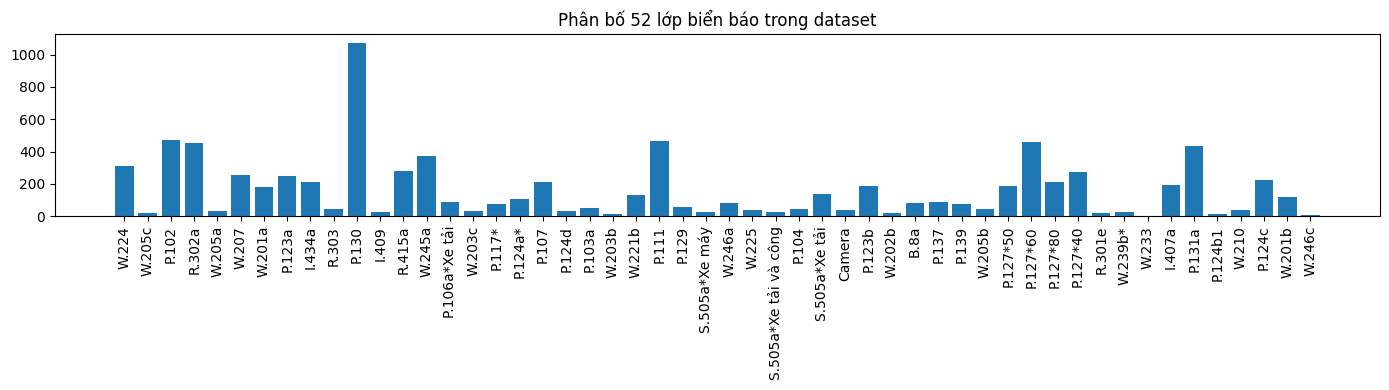

Lớp nhiều nhất: (np.int64(10), 1071)
Lớp ít nhất: (np.int64(44), 3)
Mất cân bằng (max/min ratio): 357.0


In [15]:
import matplotlib.pyplot as plt
from collections import Counter

all_labels = list(y_train) + list(y_test)
class_counts = Counter(all_labels)
plt.figure(figsize=(14, 4))
plt.bar([classes[c] for c in sorted(class_counts)], [class_counts[c] for c in sorted(class_counts)])
plt.xticks(rotation=90)
plt.title(f"Phân bố {len(class_counts)} lớp biển báo trong dataset")
plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution.png")
plt.show()

print("Lớp nhiều nhất:", max(class_counts.items(), key=lambda x: x[1]))
print("Lớp ít nhất:", min(class_counts.items(), key=lambda x: x[1]))
print("Mất cân bằng (max/min ratio):", max(class_counts.values()) / min(class_counts.values()))

**Pipeline demo end-to-end: ảnh thô → detect (YOLO) → crop → classify (CNN) → kết quả**


--- 0857.jpg ---
Phát hiện bbox (255,162,363,260) → phân loại: W.207
Phát hiện bbox (250,270,359,368) → phân loại: W.224


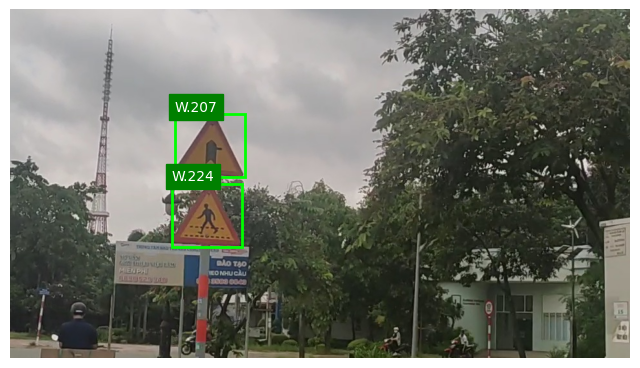


--- 1683.jpg ---
Phát hiện bbox (416,167,449,198) → phân loại: P.104
Phát hiện bbox (375,112,404,141) → phân loại: P.127*60
Phát hiện bbox (341,112,372,141) → phân loại: P.127*80
Phát hiện bbox (888,280,915,306) → phân loại: P.127*50
Phát hiện bbox (887,249,915,277) → phân loại: P.103a


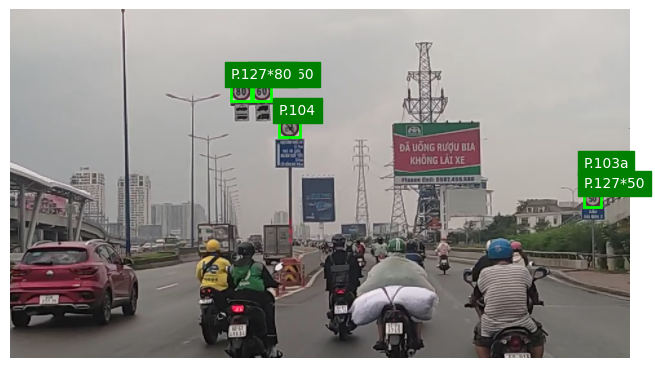


--- 1049.jpg ---
Phát hiện bbox (547,179,581,206) → phân loại: W.224
Phát hiện bbox (547,143,581,177) → phân loại: P.124a*
Phát hiện bbox (288,100,321,134) → phân loại: P.111
Phát hiện bbox (289,64,323,98) → phân loại: P.130
Phát hiện bbox (209,207,222,219) → phân loại: P.102
Phát hiện bbox (209,218,223,230) → phân loại: R.302a


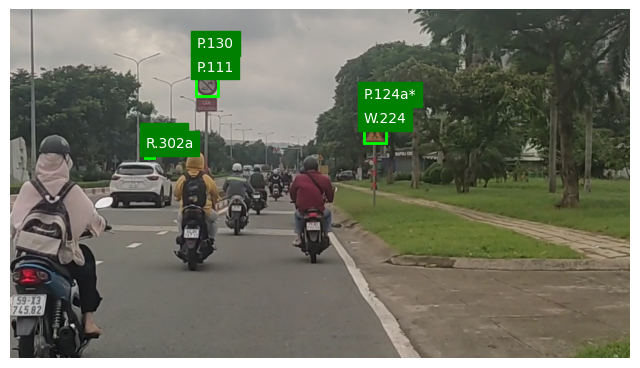

In [16]:
import cv2
import matplotlib.pyplot as plt

def full_pipeline_demo(img_path, conf_thres=0.25):
    results = model_yolo.predict(img_path, conf=conf_thres, verbose=False)
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)

    boxes = results[0].boxes
    if len(boxes) == 0:
        print("Không phát hiện biển báo nào.")
        return

    for box in boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
        crop = img[y1:y2, x1:x2]
        crop_resized = cv2.resize(crop, (64, 64)).astype(np.float32) / 255.0
        crop_tensor = torch.tensor(crop_resized).permute(2, 0, 1).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            pred_idx = model(crop_tensor).argmax(1).item()
        pred_class = classes[unique_classes[pred_idx]]

        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="lime", linewidth=2))
        ax.text(x1, y1-5, pred_class, color="white", fontsize=10, backgroundcolor="green")
        print(f"Phát hiện bbox ({x1},{y1},{x2},{y2}) → phân loại: {pred_class}")

    plt.axis("off")
    plt.savefig("/kaggle/working/demo_result.png", bbox_inches="tight")
    plt.show()

# thử demo với vài ảnh test
for fname in test_files[:3]:
    print(f"\n--- {fname} ---")
    full_pipeline_demo(f"{BASE}/images/{fname}")